Number of nodes: 34
Number of edges: 78


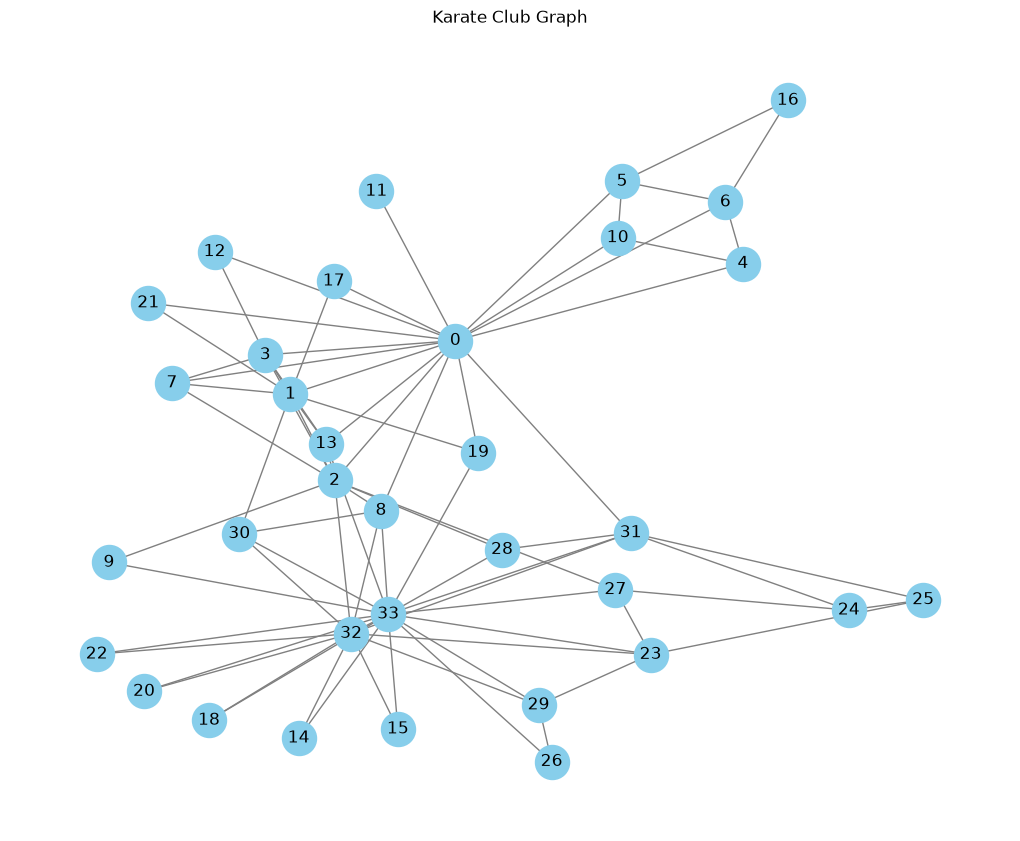

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Load the Karate Club graph
G = nx.karate_club_graph()

nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

# Fixed graph layout
pos = nx.spring_layout(G, seed=42, weight=None)

# Display graph information
print("Number of nodes:", n)
print("Number of edges:", m)

# Visualize the graph
plt.figure(figsize=(10, 8))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=600,
    edge_color="gray"
)

plt.title("Karate Club Graph")
plt.show()

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

k = np.sum(A, axis=1)

B = A - np.outer(k, k) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)

print("Modularity matrix:")
print(B)


Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Modularity matrix:
[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]


In [3]:
def modularity(communities):
    Q = 0

    for community in communities:
        indices = [nodes.index(i) for i in community]
        Q += B[np.ix_(indices, indices)].sum()

    return Q / (2 * m)

In [4]:
def spectral_split(community):

    indices = [nodes.index(i) for i in community]

    B_sub = B[np.ix_(indices, indices)]

    B_sub = B_sub - np.diag(B_sub.sum(axis=1))

    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)

    largest_eigenvalue = eigenvalues[-1]
    leading_eigenvector = eigenvectors[:, -1]

    if largest_eigenvalue <= 1e-10:
        return None

    C1 = []
    C2 = []

    for i, node in enumerate(community):
        if leading_eigenvector[i] > 0:
            C1.append(node)
        else:
            C2.append(node)

    if not C1 or not C2:
        return None

    s = np.where(leading_eigenvector > 0, 1, -1)

    delta_Q = (s.T @ B_sub @ s) / (4 * m)

    if delta_Q <= 1e-10:
        return None

    return C1, C2

In [5]:
def visualize(communities, iteration):

    plt.figure(figsize=(10, 7))

    colors = plt.get_cmap("tab20", len(communities))

    nx.draw_networkx_edges(G, pos, alpha=0.5)

    for i, community in enumerate(communities):

        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=community,
            node_color=[colors(i)],
            label=f"Community {i + 1}",
            node_size=500
        )

    nx.draw_networkx_labels(G, pos)

    plt.title(
        f"Iteration {iteration} | "
        f"Modularity = {modularity(communities):.4f}"
    )

    plt.legend()
    plt.axis("off")
    plt.show()

In [6]:
metric_history = {
    "Degree Centrality": {},
    "Betweenness Centrality": {},
    "Closeness Centrality": {},
    "Clustering Coefficient": {}
}


def calculate_metrics(communities, iteration):

    metrics = {
        name: {} for name in metric_history
    }

    for community in communities:

        H = G.subgraph(community)

        metrics["Degree Centrality"].update(
            nx.degree_centrality(H)
        )

        metrics["Betweenness Centrality"].update(
            nx.betweenness_centrality(H)
        )

        metrics["Closeness Centrality"].update(
            nx.closeness_centrality(H)
        )

        metrics["Clustering Coefficient"].update(
            nx.clustering(H)
        )

    for name in metrics:
        metric_history[name][iteration] = metrics[name]

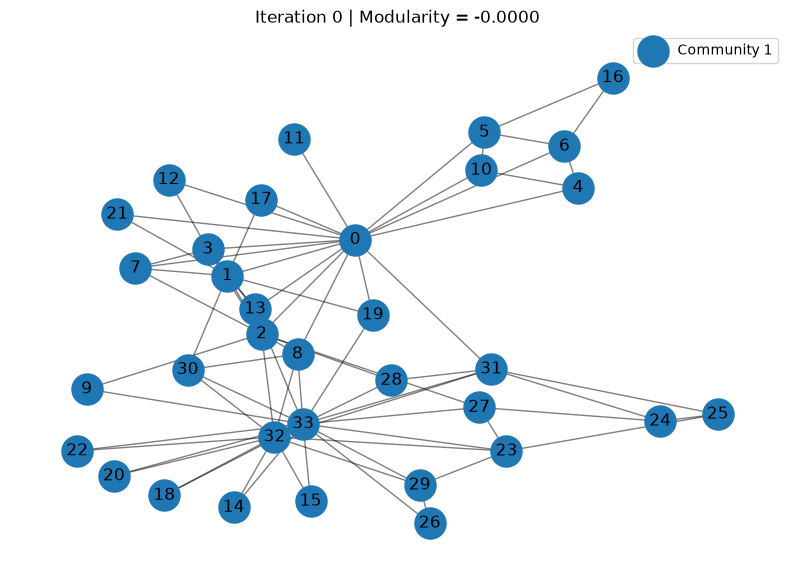

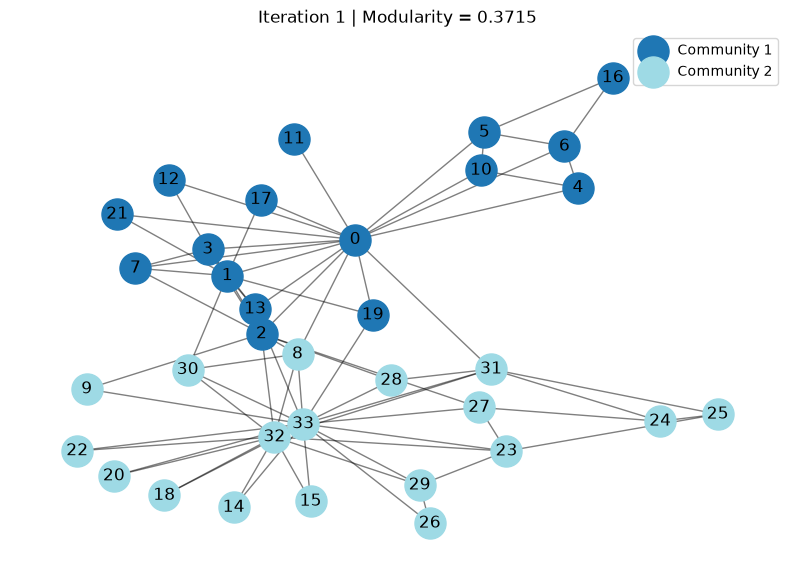

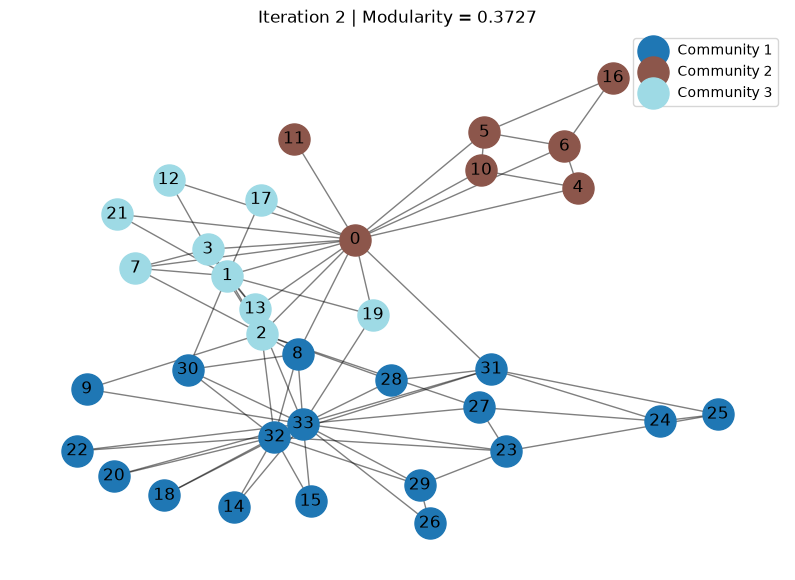

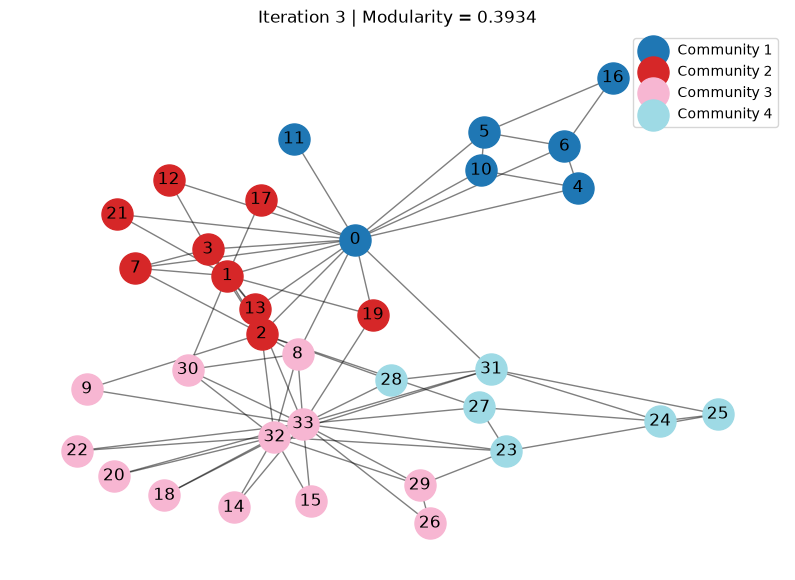

Final number of communities: 4
Community 1: [0, 4, 5, 6, 10, 11, 16]
Community 2: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 3: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: [23, 24, 25, 27, 28, 31]
Final modularity: 0.3934089414858646


In [7]:
communities = [nodes.copy()]
iteration = 0
modularity_history = []

for name in metric_history:
    metric_history[name].clear()


def record_iteration():

    modularity_history.append(
        modularity(communities)
    )

    visualize(communities, iteration)
    calculate_metrics(communities, iteration)


def recursive_split(community):

    global iteration

    result = spectral_split(community)

    if result is None:
        return

    C1, C2 = result

    communities.remove(community)
    communities.extend([C1, C2])

    iteration += 1

    record_iteration()

    recursive_split(C1)
    recursive_split(C2)


record_iteration()

recursive_split(nodes.copy())

print("Final number of communities:", len(communities))

for i, community in enumerate(communities):
    print(f"Community {i + 1}: {sorted(community)}")

print("Final modularity:", modularity(communities))

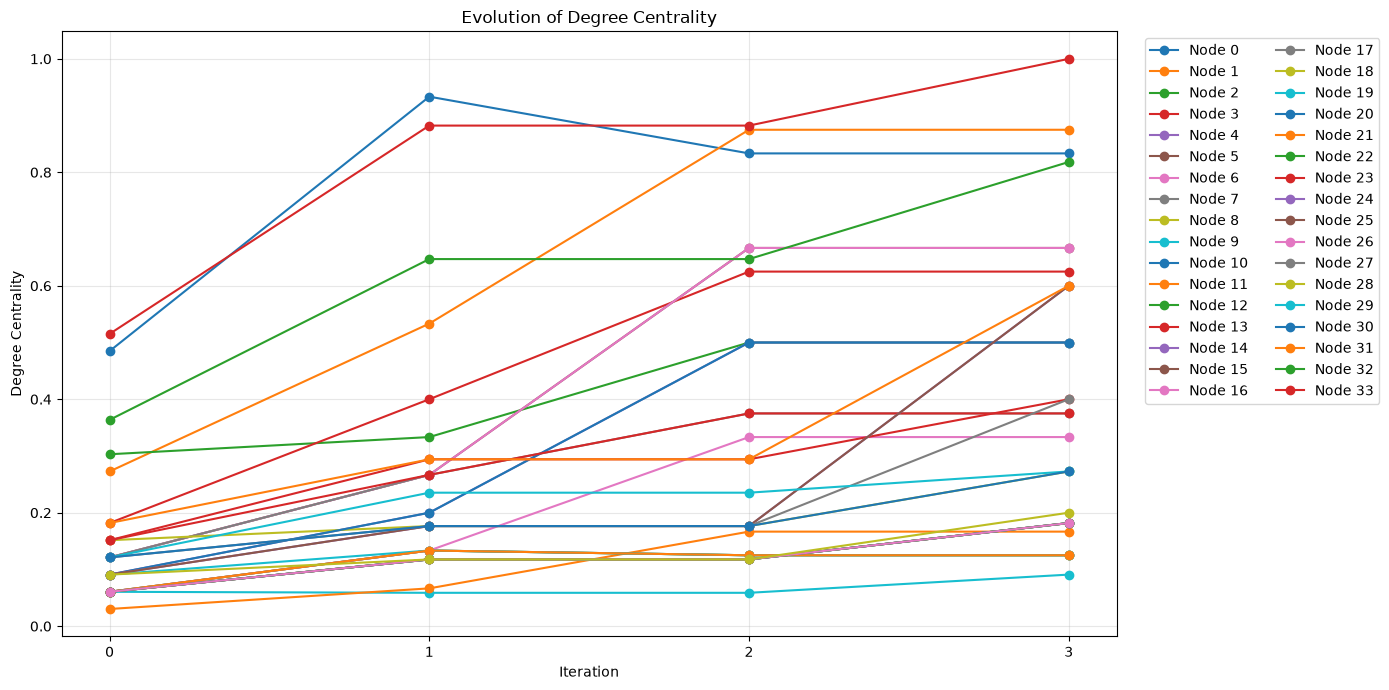

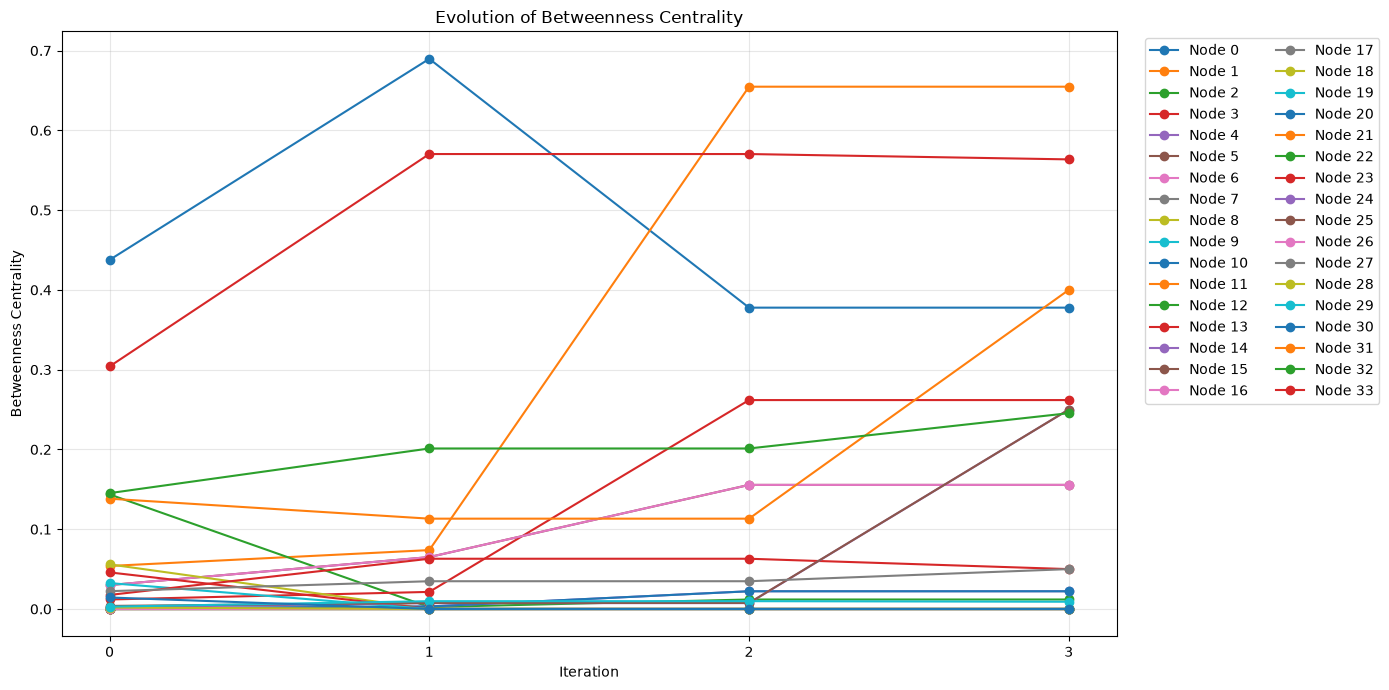

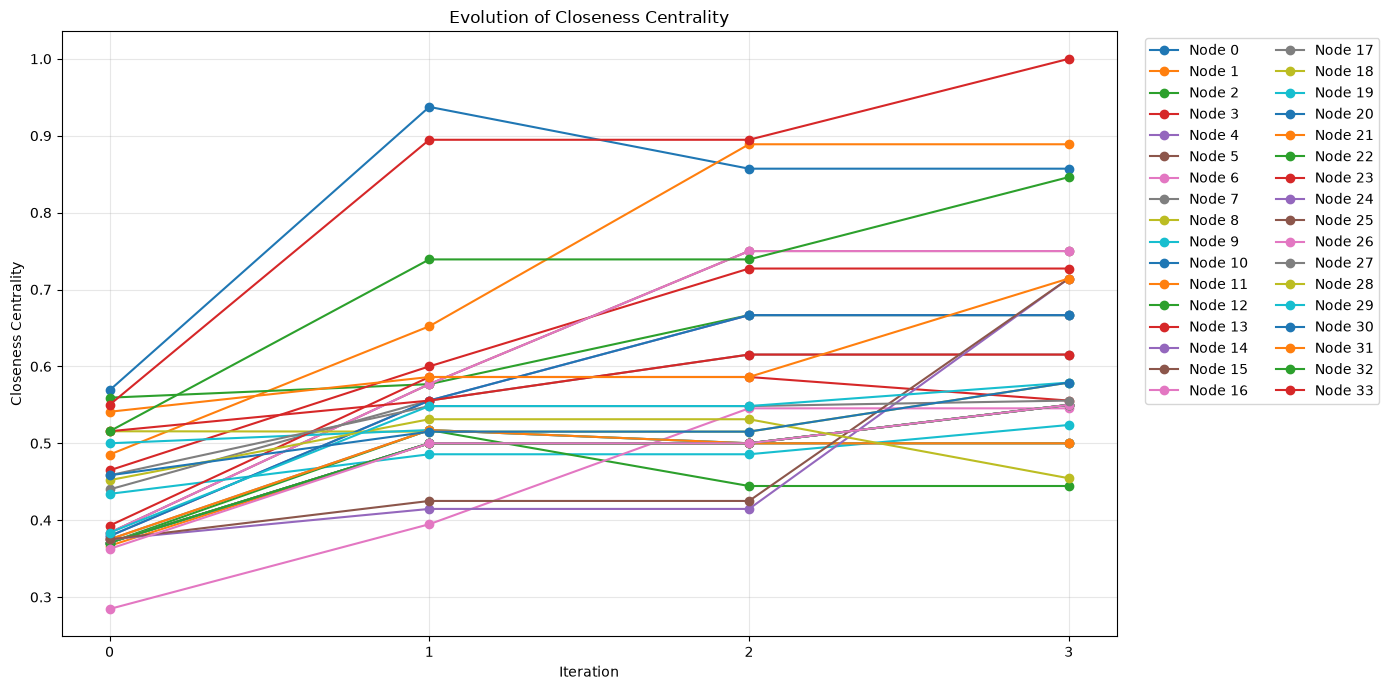

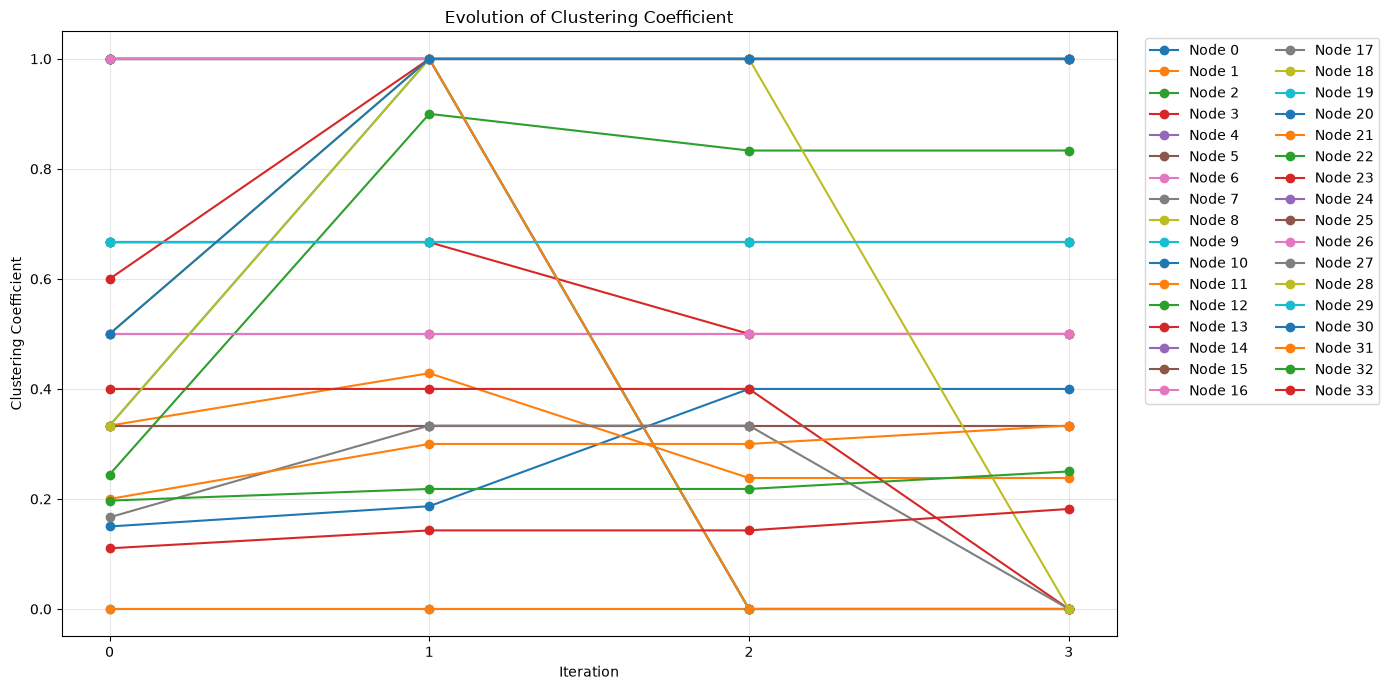

In [8]:
for name, history in metric_history.items():

    plt.figure(figsize=(14, 7))

    df = pd.DataFrame.from_dict(
        history, orient="index"
    ).sort_index()

    for node in nodes:

        plt.plot(
            df.index,
            df[node],
            marker="o",
            label=f"Node {node}"
        )

    plt.title(f"Evolution of {name}")
    plt.xlabel("Iteration")
    plt.ylabel(name)

    plt.xticks(df.index)
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        ncol=2
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

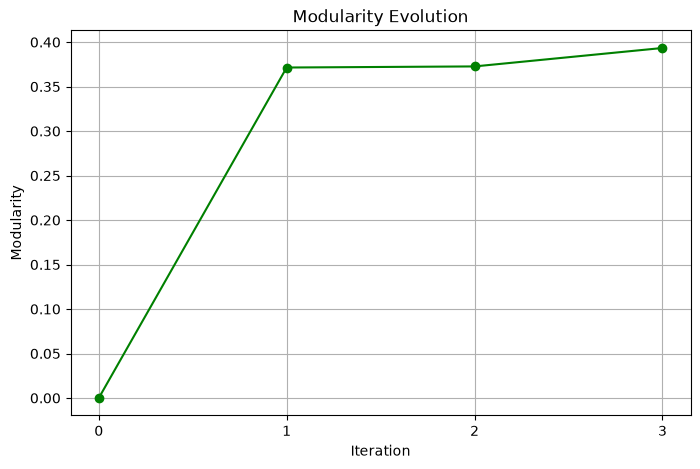

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(modularity_history)),
    modularity_history,
    marker="o",
    color="green"
)

plt.title("Modularity Evolution")
plt.xlabel("Iteration")
plt.ylabel("Modularity")
plt.xticks(range(len(modularity_history)))
plt.grid()
plt.show()

In [10]:
for name, history in metric_history.items():

    df = pd.DataFrame.from_dict(
        history, orient="index"
    )

    average = df.mean(axis=0)

    print(f"\n{name}")
    print("Top 5 nodes across iterations:")

    print(average.nlargest(5).round(4))


Degree Centrality
Top 5 nodes across iterations:
33    0.8200
0     0.7712
1     0.6390
32    0.6190
3     0.4580
dtype: float64

Betweenness Centrality
Top 5 nodes across iterations:
33    0.5021
0     0.4707
1     0.3593
32    0.1983
31    0.1912
dtype: float64

Closeness Centrality
Top 5 nodes across iterations:
33    0.8349
0     0.8052
1     0.7288
32    0.7100
3     0.6298
dtype: float64

Clustering Coefficient
Top 5 nodes across iterations:
7     1.0
14    1.0
15    1.0
16    1.0
18    1.0
dtype: float64


## Discussion

The spectral modularity algorithm divided the Karate
Club graph into four communities with a final
modularity score of 0.3934.

Nodes 33, 0, 1 and 32 achieved the highest average
degree, betweenness and closeness centrality scores
across the iterations.

Nodes 7, 14, 15, 16 and 18 achieved an average
clustering coefficient of 1.0.

Community splitting affects centrality by changing
the connections and shortest paths available within
each community.

The modularity score increased after every accepted
split, indicating an improvement in partition quality.

## References

1. Newman, M. E. J. (2006).
   Modularity and community structure in networks.
   PNAS, 103(23), 8577–8582.

2. Zachary, W. W. (1977).
   An information flow model for conflict and fission
   in small groups.